In [40]:
# -------------------------------------------
# 
# plot GCAM and SCEPTER derived CDR estimates
# 
# -------------------------------------------
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

In [41]:
# --- read in data
#
#  ----------------------------------------------------------------
# [ RUN NAMES ]
# exe_central1p5 ; exe_central2p0 ; exe_limBio1p5 ; exe_lowCCS1p5 ; 
# exe_lowCDR1p5 ; exe_noBiochar1p5 ; exe_noWeathering1p5 ; 
# exe_ref1p5 ; exe_techBehaviorChange1p5 ; exe_techBehaviorChange2p0 ;
# ----------------------------------------------------------------
#
EXP_SETS = [
    "exe_central1p5", "exe_lowCDR1p5", 
    "exe_noWeathering1p5", "exe_techBehaviorChange1p5"
]
# 
# ************************************************
# --- SCEPTER outputs
EXP_GROUP = "gcam_opr_psdfull_nocec"
idx = "001"
fn_cdr = "ds_cdr.zarr"   # time-integrated data
fn_cdr_trans = "ds_cdr_transient.zarr"  # time-transient data
# 
ds_dict = {}
ds_trans_dict = {}
for EXP_SET in EXP_SETS:
    dir_postproc = f's3://carbonplan-carbon-removal/ew-workflows-data/scepter/postprocessed/{EXP_GROUP}/{EXP_SET}_{idx}'
    # [ read in ]
    ds_dict[EXP_SET] = xr.open_zarr(os.path.join(dir_postproc, fn_cdr))
    ds_trans_dict[EXP_SET] = xr.open_zarr(os.path.join(dir_postproc, fn_cdr_trans))

# ************************************************
# --- GCAM outputs
run_format = 'one-cell-per-region'
deg_resolution = 1
gcam_fn = f'annual_rockflx_densest-ag-region_{deg_resolution}deg.pkl'
df_dict = {}
for EXP_SET in EXP_SETS:
    gcam_dir = f's3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/{run_format}/{EXP_SET}'
    # [ read in ]
    df_dict[EXP_SET] = pd.read_pickle(os.path.join(gcam_dir, gcam_fn))

# ************************************************
# --- derived ag map 
# ( only need one ag map )
run_format = 'one-cell-per-region'
deg_resolution = 1
gcam_dir = f's3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/{run_format}/{EXP_SET}'
gcam_fn = f'cropland+gcamRegions_time_{deg_resolution}deg.zarr'
# [ read in ]
dsag = xr.open_zarr(os.path.join(gcam_dir, gcam_fn))

In [42]:
# --- compute global GCAM CDR 
df_global_dict = {}
for key, tdf in df_dict.items():
    df_global_dict[key] = (
        tdf.groupby("time", as_index=False)["gcam_gross_cdr_mtCO2"]
        .sum()
        .assign(region="globe")
    )

## Calculate global CDR from SCEPTER outputs
Each pixel (or site) in SCEPTER outputs CDR in tonnes/ha. If we have one pixel per region, then we need to muliply by the cropland area in the region to get the total tonnes. 

Note that the cropland area units are m2. 1 ha = 1 m2/1000.

In [43]:
# [ list vars to scale by area ] -----------------------
vars_to_scale_by_area = [
    'cdr_adv', 'cdr_adv_plus_newSIC', 'cdr_dif', 'cdr_dif_component',
    'cdr_resp_component', 'cdr_resp_component_noAE', 'cdr_SIConly', 
    'co2pot_adv_tonHa_camg', 'co2pot_adv_tonHa_totcat', 'co2pot_tot_tonHa_camg',
    'co2pot_tot_tonHa_totcat', 'DICpot_adv_camg', 'DICpot_adv_totcat',
    'int_dust_ton_ha_yr', 
]
vars_to_scale_by_area_trans = [
    'cdr_adv', 'cdr_adv_plus_newSIC', 'cdr_dif', 'cdr_dif_component',
    'cdr_resp_component', 'cdr_resp_component_noAE', 'cdr_SIConly', 
    'co2pot_adv_tonHaYr_camg', 'co2pot_adv_tonHaYr_totcat', 'co2pot_tot_tonHaYr_camg',
    'co2pot_tot_tonHaYr_totcat', 'DICpot_adv_camg', 'DICpot_adv_totcat',
    'int_dust_ton_ha_yr', 
]
# ------------------------------------------------------
# 
for EXP_SET in EXP_SETS:
    # pull out data
    df = df_dict[EXP_SET]
    # 
    # --- calculate global annual CDR 
    # [ get cropland area for each region ]
    dfreg_t0 = df.groupby("region", as_index=False).first().copy() # df of regional data (1 row / region, no time)
    dfreg_t0['cropland_area_by_region'] = dsag["cropland_area_by_region"].sel(
        y=xr.DataArray(dfreg_t0["lat"].values, dims="points"),
        x=xr.DataArray(dfreg_t0["lon"].values, dims="points"),
    )
    # convert area from m2 to hectares
    dfreg_t0['cropland_area_by_region_hectares'] = dfreg_t0['cropland_area_by_region'] / 1e4
    # align df regions to ds sites for later calculation
    area_series = (
        dfreg_t0.set_index("region_nospaces")["cropland_area_by_region_hectares"]
    )
    area_series.index.name = "site"
    area_da = xr.DataArray(
        area_series,
        dims="site",
        coords={"site": area_series.index}
    )
    # 
    # =========================================================================
    for var in vars_to_scale_by_area:
        # [ calculate vars in tonnes / yr for each region (multiply by hectares) ]
        ds_dict[EXP_SET][f'{var}_xCropArea'] = ds_dict[EXP_SET][var] * area_da
        ds_dict[EXP_SET][f'{var}_xCropArea'].attrs['note'] = f"Var {var} multiplied by regional hectares of cropland"
    for var_trans in vars_to_scale_by_area_trans:
        # [ repeat for transient data ]
        ds_trans_dict[EXP_SET][f'{var_trans}_xCropArea'] = ds_trans_dict[EXP_SET][var_trans] * area_da
        ds_trans_dict[EXP_SET][f'{var_trans}_xCropArea'].attrs['note'] = f"Var {var_trans} multiplied by regional hectares of cropland"

In [44]:
# --- apply rock feedstock RCO2 correction
cdr_vars = [
    'cdr_adv', 'cdr_adv_plus_newSIC', 'cdr_dif', 'cdr_dif_component',
    'cdr_resp_component', 'cdr_resp_component_noAE', 'cdr_SIConly', 
    'co2pot_adv_tonHa_camg', 'co2pot_adv_tonHa_totcat', 'co2pot_tot_tonHa_camg',
    'co2pot_tot_tonHa_totcat', 'DICpot_adv_camg', 'DICpot_adv_totcat',
]
cdr_vars_trans = [
    'cdr_adv', 'cdr_adv_plus_newSIC', 'cdr_dif', 'cdr_dif_component',
    'cdr_resp_component', 'cdr_resp_component_noAE', 'cdr_SIConly', 
    'co2pot_adv_tonHaYr_camg', 'co2pot_adv_tonHaYr_totcat', 'co2pot_tot_tonHaYr_camg',
    'co2pot_tot_tonHaYr_totcat', 'DICpot_adv_camg', 'DICpot_adv_totcat',
]
# =========================================================================
rco2_gcam = 0.3
rco2_gbas = 0.41
corr_factor = rco2_gcam / rco2_gbas
for EXP_SET in EXP_SETS:
    for var in vars_to_scale_by_area:
        # [ calculate vars in tonnes / yr for each region (multiply by hectares) ]
        ds_dict[EXP_SET][f'{var}_xCropArea_corr'] = ds_dict[EXP_SET][f'{var}_xCropArea'] * corr_factor
        ds_dict[EXP_SET][f'{var}_xCropArea_corr'].attrs['note'] = f"Var {var} multiplied by regional hectares of cropland and corrected for different feedstock RCO2 compared to gcam"
    for var_trans in vars_to_scale_by_area_trans:
        # [ repeat for transient data ]
        ds_trans_dict[EXP_SET][f'{var_trans}_xCropArea_corr'] = ds_trans_dict[EXP_SET][f'{var_trans}_xCropArea'] * corr_factor
        ds_trans_dict[EXP_SET][f'{var_trans}_xCropArea_corr'].attrs['note'] = f"Var {var} multiplied by regional hectares of cropland and corrected for different feedstock RCO2 compared to gcam"

## Plot scepter vs gcam cases

### Timeseries

Text(0, 0.5, 'Gt CO2/yr')

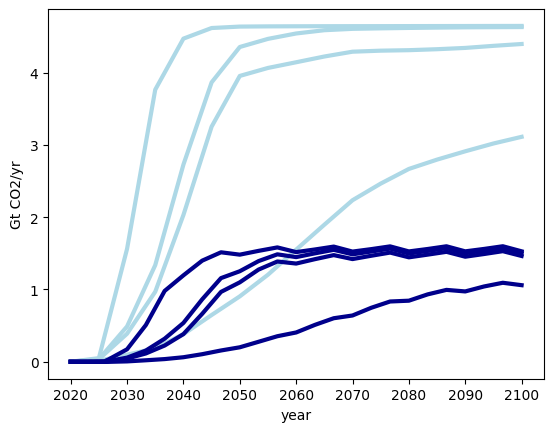

In [45]:
# [ get global sum of CDR ]

for EXP_SET in EXP_SETS: # gcam data 
    df_global = df_global_dict[EXP_SET]
    plt.plot(df_global['time'], df_global['gcam_gross_cdr_mtCO2']/1e3, c='lightblue', linewidth=3)
for EXP_SET in EXP_SETS: # scepter data
    tds_trans = ds_trans_dict[EXP_SET]
    plt.plot(tds_trans.time+2020, tds_trans['cdr_adv_xCropArea_corr'].sum('site')/1e9, c='darkblue', linewidth=3)
plt.xlabel('year')
plt.ylabel('Gt CO2/yr')

### SCEPTER fraction GCAM integrated CDR

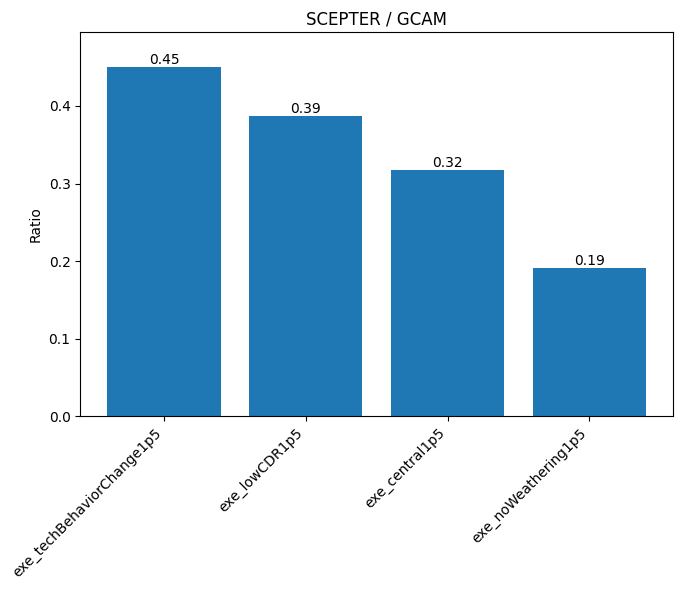

In [39]:
# --- compute time-integrated CDR in Gt
gcam_int = []
scepter_int = []
ratio_int = []
exps = []
for EXP_SET in EXP_SETS:
    exps.append(EXP_SET)
    df_global = df_global_dict[EXP_SET]
    tds = ds_dict[EXP_SET]
    # get integrated cdr timeseries
    gcam_tmp = df_global['gcam_gross_cdr_mtCO2'].cumsum() / 1e3   # [Gt]
    scepter_tmp = ds_dict[EXP_SET]['cdr_adv_xCropArea_corr'].sum('site')/1e9  # [Gt]
    # get final values
    gcam_int.append(gcam_tmp.values[-1])
    scepter_int.append(scepter_tmp.values[-1])
    ratio_int.append(scepter_tmp.values[-1] / gcam_tmp.values[-1])

# --- sort by height
idx = np.argsort(ratio_int)[::-1]
exps_sorted = np.array(exps)[idx]
ratio_sorted = np.array(ratio_int)[idx]

# --- PLOT
fig, ax = plt.subplots(figsize=(7, 6))

bars = ax.bar(exps_sorted, ratio_sorted)

ax.set_ylabel("Ratio")
ax.set_title("SCEPTER / GCAM")
ax.set_ylim(0, max(ratio_int) * 1.1)

# optional: add value labels on top
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

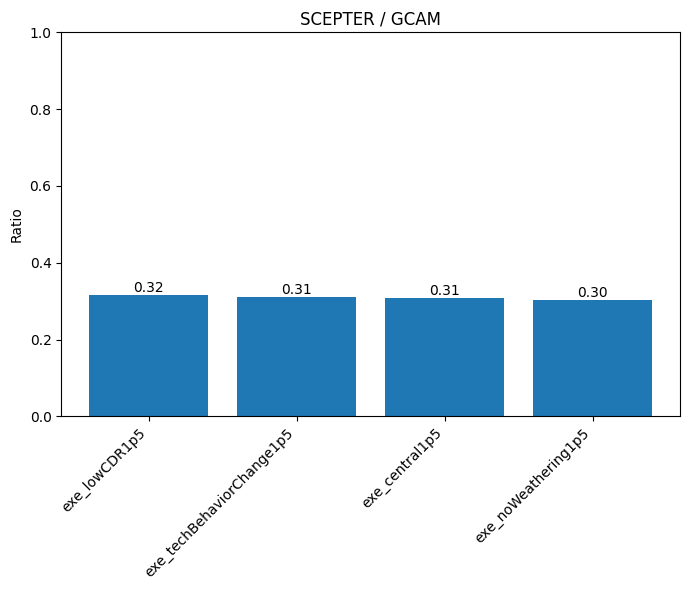

In [47]:
# --- compute time-integrated CDR in Gt
gcam_int = []
scepter_int = []
ratio_int = []
exps = []
for EXP_SET in EXP_SETS:
    exps.append(EXP_SET)
    df_global = df_global_dict[EXP_SET]
    tds = ds_dict[EXP_SET]
    # get integrated cdr timeseries
    gcam_tmp = df_global['gcam_gross_cdr_mtCO2'].cumsum() / 1e3   # [Gt]
    scepter_tmp = ds_dict[EXP_SET]['cdr_adv_xCropArea_corr'].sum('site')/1e9  # [Gt]
    # get final values
    gcam_int.append(gcam_tmp.values[-1])
    scepter_int.append(scepter_tmp.values[-1])
    ratio_int.append(scepter_tmp.values[-1] / gcam_tmp.values[-1])

# --- sort by height
idx = np.argsort(ratio_int)[::-1]
exps_sorted = np.array(exps)[idx]
ratio_sorted = np.array(ratio_int)[idx]

# --- PLOT
fig, ax = plt.subplots(figsize=(7, 6))

bars = ax.bar(exps_sorted, ratio_sorted)

ax.set_ylabel("Ratio")
ax.set_title("SCEPTER / GCAM")
ax.set_ylim(0, max(ratio_int) * 1.1)

# optional: add value labels on top
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.xticks(rotation=45, ha="right")
plt.ylim(0,1)
plt.tight_layout()
plt.show()

Text(0, 0.5, 'Gt CO2/yr')

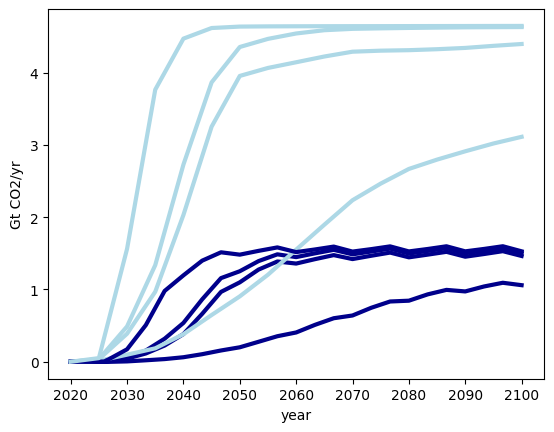

In [9]:
# [ get global sum of CDR ]

for EXP_SET in EXP_SETS:
    tds_trans = ds_trans_dict[EXP_SET]
    df_global = df_global_dict[EXP_SET]
    plt.plot(tds_trans.time+2020, tds_trans['cdr_adv_xCropArea_corr'].sum('site')/1e9, c='darkblue', linewidth=3)
    plt.plot(df_global['time'], df_global['gcam_gross_cdr_mtCO2']/1e3, c='lightblue', linewidth=3)
plt.xlabel('year')
plt.ylabel('Gt CO2/yr')